In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

base_path = "/content/drive/MyDrive/ML-Capstone-Project"
df = pd.read_csv(f"{base_path}/data/clean_housing.csv")

Mounted at /content/drive


In [2]:
features = [c for c in df.columns if c not in ["median_house_value","is_expensive"]]
X = df[features].values
y_reg = df["median_house_value"].values
y_clf = df["is_expensive"].values

X_tr, X_te, ytr_reg, yte_reg = train_test_split(X, y_reg, test_size=0.2, random_state=42)
Xtr_c, Xte_c, ytr_clf, yte_clf = train_test_split(X, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

scaler = StandardScaler()
X_tr_s, X_te_s = scaler.fit_transform(X_tr), scaler.transform(X_te)
Xtr_cs, Xte_cs = scaler.fit_transform(Xtr_c), scaler.transform(Xte_c)

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression().fit(X_tr_s, ytr_reg)
pred = lr.predict(X_te_s)

mse = mean_squared_error(yte_reg, pred)
rmse = np.sqrt(mse)
r2 = r2_score(yte_reg, pred)
print(f"MSE  = {mse:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R²   = {r2:.3f}")

MSE  = 5042552462.75
RMSE = 71010.93
R²   = 0.615


Accuracy: 0.8287306201550387
              precision    recall  f1-score   support

           0       0.83      0.82      0.83      2065
           1       0.82      0.84      0.83      2063

    accuracy                           0.83      4128
   macro avg       0.83      0.83      0.83      4128
weighted avg       0.83      0.83      0.83      4128



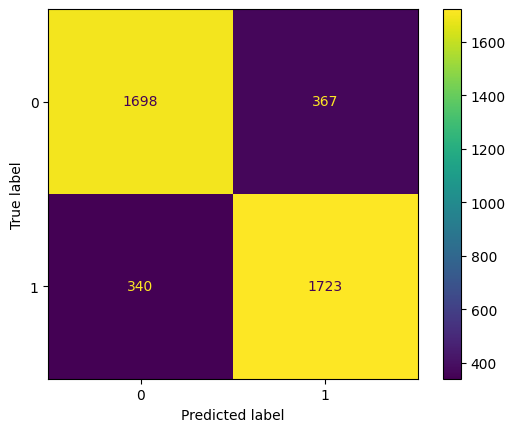

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

clf = LogisticRegression(max_iter=1000).fit(Xtr_cs, ytr_clf)
yhat = clf.predict(Xte_cs)

print("Accuracy:", accuracy_score(yte_clf, yhat))
print(classification_report(yte_clf, yhat))
ConfusionMatrixDisplay.from_predictions(yte_clf, yhat)
plt.show()

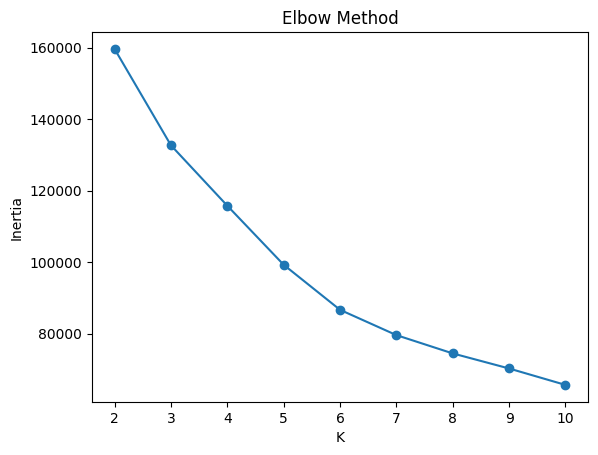

In [5]:
from sklearn.cluster import KMeans

inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_tr_s)
    inertias.append(km.inertia_)

plt.plot(list(K_range), inertias, marker="o")
plt.xlabel("K"); plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

Silhouette Score: 0.2667616599399251


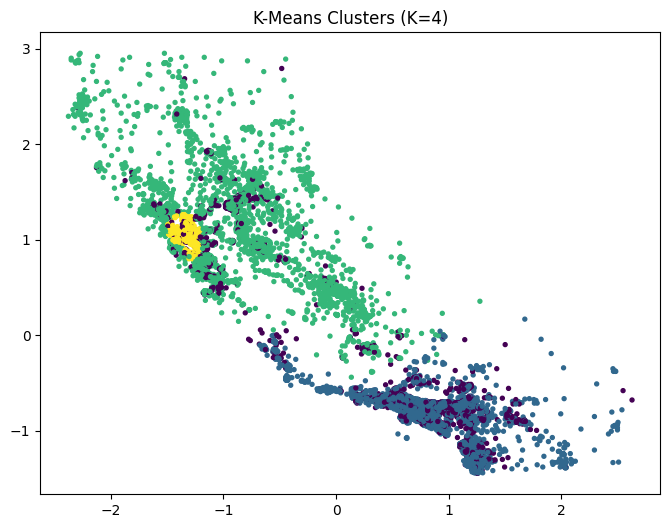

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K = 4  # اختار من الرسمة
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X_tr_s)
labels = km.labels_

print("Silhouette Score:", silhouette_score(X_tr_s, labels))

plt.figure(figsize=(8,6))
plt.scatter(X_tr_s[:,0], X_tr_s[:,1], c=labels, cmap="viridis", s=8)
plt.title(f"K-Means Clusters (K={K})")
plt.show()